# Практична робота 2

## Дослідницький аналіз і підготовка даних

**Дисципліна:** Розпізнавання образів та класичне машинне навчання
**Студент:** Святішенко Дмитро
**Група:** ІН-32/2
**Дата виконання:** 28.10.2026

### Мета роботи

Навчитися аналізувати якість табличних даних, виявляти та виправляти пропуски,
дублікати, неправильні типи й аномальні значення, кодувати категоріальні ознаки
та формувати навчальну і тестову вибірки.

## 1. Підключення бібліотек

Підключаються бібліотеки для роботи з таблицями, числовими даними, візуалізацією,
збереженням метаданих і формуванням train/test-вибірок.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from IPython.display import display

In [2]:
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.12.11
NumPy: 2.5.3
pandas: 3.0.6
scikit-learn: 1.9.1


## 2. Підключення Google Drive

Google Drive використовується для читання початкових даних і збереження результатів очищення.
Якщо Notebook запущено поза Colab (локально в Jupyter), Drive не підключається,
а робочою папкою вважається корінь репозиторію.

In [3]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print("Notebook виконується поза Google Colab — використовується локальна папка проєкту.")

Notebook виконується поза Google Colab — використовується локальна папка проєкту.


### 2.1. Створення шляхів

In [4]:
if IN_COLAB:
    PROJECT_DIR = Path("/content/drive/MyDrive/pattern-recognition-practice")
else:
    # Notebook лежить у папці notebooks/, тому корінь проєкту — на рівень вище
    PROJECT_DIR = Path.cwd().parent

DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
REPORTS_DIR = PROJECT_DIR / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

SOURCE_PATH = DATA_DIR / "iris.csv"
DIRTY_PATH = DATA_DIR / "iris_dirty.csv"
CLEANED_PATH = PROCESSED_DIR / "iris_cleaned.csv"

X_TRAIN_PATH = PROCESSED_DIR / "X_train.csv"
X_TEST_PATH = PROCESSED_DIR / "X_test.csv"
Y_TRAIN_PATH = PROCESSED_DIR / "y_train.csv"
Y_TEST_PATH = PROCESSED_DIR / "y_test.csv"

SUMMARY_PATH = REPORTS_DIR / "preprocessing_summary.csv"
CLASS_MAPPING_PATH = REPORTS_DIR / "class_mapping.json"

DATA_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Папка проєкту:", PROJECT_DIR.name)
print("Папка початкових даних:", DATA_DIR.relative_to(PROJECT_DIR))
print("Папка підготовлених даних:", PROCESSED_DIR.relative_to(PROJECT_DIR))
print("Папка звітів:", REPORTS_DIR.relative_to(PROJECT_DIR))

Папка проєкту: pattern-recognition-practice
Папка початкових даних: data
Папка підготовлених даних: data\processed
Папка звітів: reports


## 3. Завантаження початкового набору Iris

Спочатку перевіряється наявність файла `iris.csv`, створеного у практичній роботі 1.
Якщо файл відсутній, він створюється повторно.

In [5]:
if SOURCE_PATH.exists():
    source_df = pd.read_csv(SOURCE_PATH)
    print("Початковий файл завантажено.")
else:
    print("Файл iris.csv не знайдено. Створюємо його повторно.")

    iris = load_iris(as_frame=True)
    source_df = iris.frame.copy()

    source_df["species"] = source_df["target"].map(
        {
            0: "setosa",
            1: "versicolor",
            2: "virginica"
        }
    )

    source_df = source_df.drop(columns=["target"])

    source_df = source_df.rename(
        columns={
            "sepal length (cm)": "sepal_length_cm",
            "sepal width (cm)": "sepal_width_cm",
            "petal length (cm)": "petal_length_cm",
            "petal width (cm)": "petal_width_cm"
        }
    )

    source_df.to_csv(SOURCE_PATH, index=False)
    print("Файл iris.csv створено:", SOURCE_PATH)

display(source_df.head())

Початковий файл завантажено.


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [6]:
print("Розмір початкової таблиці:", source_df.shape)

Розмір початкової таблиці: (150, 5)


## 4. Створення набору з контрольованими проблемами

Для навчальних цілей до початкового набору додаються типові проблеми, які можуть виникати
під час збирання реальних даних: категоріальна ознака `measurement_device`, пропуски,
неузгоджені назви категорій, текстові записи в числовому стовпці, фізично неможливі
й надзвичайно великі значення та дублікати. Для відтворюваності використовується
фіксований генератор випадкових чисел. Кожен запуск починається з копії `source_df`,
тому повторне виконання комірки не додає нових дублікатів.

In [7]:
rng = np.random.default_rng(42)

dirty_df = source_df.copy()

# Додаємо категоріальну ознаку, що імітує пристрій вимірювання.
dirty_df["measurement_device"] = rng.choice(
    ["device_a", "device_b", "device_c"],
    size=len(dirty_df),
    p=[0.40, 0.35, 0.25]
)

# Додаємо пропуски в різні стовпці.
missing_plan = {
    "sepal_length_cm": 4,
    "sepal_width_cm": 5,
    "petal_length_cm": 4,
    "petal_width_cm": 5,
    "measurement_device": 4,
    "species": 2
}

for column, amount in missing_plan.items():
    selected_indices = rng.choice(
        dirty_df.index,
        size=amount,
        replace=False
    )
    dirty_df.loc[selected_indices, column] = np.nan

# Перетворюємо один числовий стовпець на object,
# щоб до нього можна було додати текстові значення.
dirty_df["sepal_length_cm"] = dirty_df["sepal_length_cm"].astype("object")

# Додаємо записи з комою, пробілами та некоректним текстом.
dirty_df.loc[3, "sepal_length_cm"] = "5,1"
dirty_df.loc[25, "sepal_length_cm"] = "unknown"
dirty_df.loc[47, "sepal_length_cm"] = " 6.3 "

# Додаємо неузгоджені варіанти назв пристроїв.
dirty_df.loc[7, "measurement_device"] = " Device_A "
dirty_df.loc[19, "measurement_device"] = "DEVICE_B"
dirty_df.loc[33, "measurement_device"] = "device c"

# Додаємо явно некоректні та надзвичайні значення.
dirty_df.loc[10, "petal_length_cm"] = -1.0
dirty_df.loc[55, "sepal_width_cm"] = 18.0
dirty_df.loc[120, "petal_width_cm"] = 9.5

# Додаємо повні дублікати.
duplicate_rows = dirty_df.iloc[[6, 27, 50, 88]].copy()

dirty_df = pd.concat(
    [dirty_df, duplicate_rows],
    ignore_index=True
)

dirty_df.to_csv(DIRTY_PATH, index=False)

print("Пошкоджений набір створено:", DIRTY_PATH.name)
print("Розмір:", dirty_df.shape)

Пошкоджений набір створено: iris_dirty.csv
Розмір: (154, 6)


### 4.1. Повторне читання файла

Після збереження та завантаження pandas повторно визначає типи даних, тому подальший аналіз
виконується для таблиці, прочитаної з диска.

In [8]:
raw_df = pd.read_csv(DIRTY_PATH)

display(raw_df.head())
print("Розмір таблиці:", raw_df.shape)

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
0,5.1,3.5,1.4,0.2,setosa,device_c
1,NaN,3.0,1.4,0.2,setosa,device_b
2,4.7,3.2,1.3,0.2,setosa,device_c
3,"5,1",3.1,1.5,0.2,setosa,device_b
4,5.0,3.6,1.4,0.2,setosa,device_a


Розмір таблиці: (154, 6)


## 5. Початковий аудит якості даних

На цьому етапі дані не виправляються. Спочатку необхідно зібрати інформацію про всі виявлені проблеми.

### 5.1. Перегляд перших і останніх рядків

In [9]:
display(raw_df.head(10))
display(raw_df.tail(10))

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
0,5.1,3.5,1.4,0.2,setosa,device_c
1,NaN,3.0,1.4,0.2,setosa,device_b
2,4.7,3.2,1.3,0.2,setosa,device_c
3,"5,1",3.1,1.5,0.2,setosa,device_b
4,5.0,3.6,1.4,0.2,setosa,device_a
5,5.4,3.9,1.7,NaN,setosa,device_c
6,4.6,3.4,1.4,0.3,setosa,device_c
7,5.0,3.4,1.5,0.2,setosa,Device_A
8,4.4,2.9,1.4,0.2,setosa,device_a
9,4.9,3.1,1.5,0.1,setosa,device_b


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
144,6.7,3.3,5.7,2.5,virginica,device_b
145,6.7,3.0,5.2,2.3,virginica,device_a
146,6.3,2.5,5.0,1.9,virginica,device_a
147,6.5,3.0,NaN,2.0,virginica,device_b
148,6.2,3.4,5.4,2.3,virginica,device_b
149,5.9,3.0,5.1,1.8,virginica,device_a
150,4.6,3.4,1.4,0.3,setosa,device_c
151,5.2,3.5,1.5,0.2,setosa,device_a
152,7.0,3.2,4.7,1.4,versicolor,device_a
153,5.6,3.0,4.1,1.3,versicolor,device_a


### 5.2. Інформація про таблицю

In [10]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 154 entries, 0 to 153
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   sepal_length_cm     150 non-null    str    
 1   sepal_width_cm      149 non-null    float64
 2   petal_length_cm     150 non-null    float64
 3   petal_width_cm      149 non-null    float64
 4   species             152 non-null    str    
 5   measurement_device  150 non-null    str    
dtypes: float64(3), str(3)
memory usage: 7.3 KB


Стовпець `sepal_length_cm` має текстовий тип (`object` у pandas 2.x, `str` у pandas 3.x),
хоча за змістом він повинен бути числовим: у ньому є записи `5,1`, ` 6.3 ` і `unknown`.

### 5.3. Зведена таблиця якості

In [11]:
quality_report = pd.DataFrame(
    {
        "data_type": raw_df.dtypes.astype(str),
        "missing_count": raw_df.isna().sum(),
        "missing_percent": (
            raw_df.isna().mean().mul(100).round(2)
        ),
        "unique_count": raw_df.nunique(dropna=True)
    }
)

display(quality_report)

,data_type,missing_count,missing_percent,unique_count
sepal_length_cm,str,4,2.60,38
sepal_width_cm,float64,5,3.25,24
petal_length_cm,float64,4,2.60,43
petal_width_cm,float64,5,3.25,23
species,str,2,1.30,3
measurement_device,str,4,2.60,6


**Відповіді на запитання.**

1. Пропуски містять **усі шість стовпців**: по 4 — `sepal_length_cm`, `petal_length_cm`, `measurement_device`; по 5 — `sepal_width_cm`, `petal_width_cm`; 2 — `species`.
2. Неправильний тип має **`sepal_length_cm`** — текстовий замість числового.
3. Цільова змінна `species` має **3** унікальні значення.
4. Категоріальна ознака `measurement_device` має **6** унікальних значень.
5. Варіантів `measurement_device` більше трьох, бо однаковий пристрій записано по-різному: `" Device_A "` (пробіли й велика літера), `DEVICE_B` (верхній регістр), `device c` (пробіл замість підкреслення). Для pandas це різні рядки.

### 5.4. Аналіз пропущених значень

In [12]:
missing_report = pd.DataFrame(
    {
        "missing_count": raw_df.isna().sum(),
        "missing_percent": (
            raw_df.isna().mean().mul(100).round(2)
        )
    }
)

missing_report = missing_report.sort_values(
    by="missing_count",
    ascending=False
)

display(missing_report)
print("Загальна кількість пропусків:", raw_df.isna().sum().sum())

,missing_count,missing_percent
sepal_width_cm,5,3.25
petal_width_cm,5,3.25
sepal_length_cm,4,2.60
petal_length_cm,4,2.60
measurement_device,4,2.60
species,2,1.30


Загальна кількість пропусків: 24


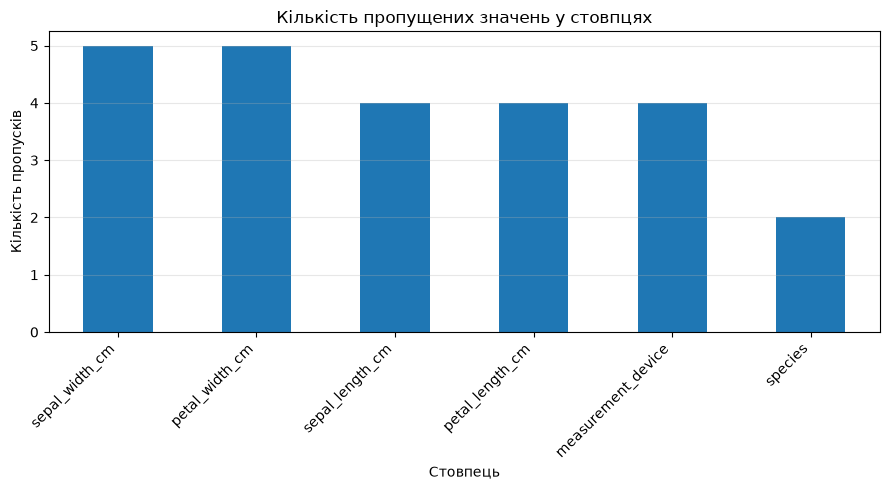

In [13]:
missing_report["missing_count"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Кількість пропущених значень у стовпцях")
plt.xlabel("Стовпець")
plt.ylabel("Кількість пропусків")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pr02_missing.png", dpi=150, bbox_inches="tight")
plt.show()

**Питання для аналізу.**

1. Найбільше пропусків мають `sepal_width_cm` і `petal_width_cm` — по 5 (3,25 %).
2. Ні, частка пропусків не критична: максимум 3,25 % у стовпці, разом 24 пропуски на 154 рядки. Видаляти всі неповні рядки недоцільно — втратилося б близько 15 % об'єктів.
3. Для числових ознак доцільно заповнення **медіаною**: вона стійка до аномальних значень.
4. Для категоріальної ознаки доцільне заповнення **модою** — найчастішою категорією.
5. Пропуски цільової змінної не заповнюють модою, бо це означало б штучно призначити квітці клас без надійної інформації; такі об'єкти видаляються.

### 5.5. Аналіз дублікатів

Параметр `keep=False` позначає всі рядки, які входять до дубльованих груп, включно з першим входженням.
Метод `raw_df.duplicated().sum()` рахує кількість зайвих повторних рядків.

In [14]:
duplicate_mask = raw_df.duplicated(keep=False)
duplicate_count = raw_df.duplicated().sum()

print("Кількість додаткових дублікатів:", duplicate_count)
print("Кількість рядків, які входять до груп дублікатів:", duplicate_mask.sum())

Кількість додаткових дублікатів: 4
Кількість рядків, які входять до груп дублікатів: 8


In [15]:
duplicates_table = raw_df.loc[duplicate_mask].sort_values(
    by=list(raw_df.columns)
)

display(duplicates_table)

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
6,4.6,3.4,1.4,0.3,setosa,device_c
150,4.6,3.4,1.4,0.3,setosa,device_c
27,5.2,3.5,1.5,0.2,setosa,device_a
151,5.2,3.5,1.5,0.2,setosa,device_a
88,5.6,3.0,4.1,1.3,versicolor,device_a
153,5.6,3.0,4.1,1.3,versicolor,device_a
50,7.0,3.2,4.7,1.4,versicolor,device_a
152,7.0,3.2,4.7,1.4,versicolor,device_a


Знайдено 4 зайві дублікати (8 рядків у чотирьох групах) — це саме рядки 6, 27, 50 і 88, додані
під час пошкодження. Повтор вимірювань двох квіток virginica, знайдений у практичній роботі 1,
більше не є повним дублікатом, оскільки ці квітки отримали різні значення `measurement_device`.

### 5.6. Аналіз неправильних типів даних

In [16]:
numeric_columns = [
    "sepal_length_cm",
    "sepal_width_cm",
    "petal_length_cm",
    "petal_width_cm"
]

print(raw_df[numeric_columns].dtypes)

sepal_length_cm        str
sepal_width_cm     float64
petal_length_cm    float64
petal_width_cm     float64
dtype: object


In [17]:
sepal_length_text = (
    raw_df["sepal_length_cm"]
    .astype("string")
    .str.strip()
    .str.replace(",", ".", regex=False)
)

sepal_length_numeric = pd.to_numeric(
    sepal_length_text,
    errors="coerce"
)

invalid_numeric_mask = (
    sepal_length_text.notna()
    & sepal_length_numeric.isna()
)

invalid_numeric_values = raw_df.loc[
    invalid_numeric_mask,
    ["sepal_length_cm"]
]

display(invalid_numeric_values)

,sepal_length_cm
25,unknown


In [18]:
invalid_numeric_summary = []

for column in numeric_columns:
    prepared_text = (
        raw_df[column]
        .astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
    )

    converted_values = pd.to_numeric(
        prepared_text,
        errors="coerce"
    )

    invalid_mask = (
        prepared_text.notna()
        & converted_values.isna()
    )

    invalid_numeric_summary.append(
        {
            "column": column,
            "invalid_count": int(invalid_mask.sum()),
            "invalid_values": raw_df.loc[
                invalid_mask,
                column
            ].astype(str).tolist()
        }
    )

invalid_numeric_summary_df = pd.DataFrame(
    invalid_numeric_summary
)

display(invalid_numeric_summary_df)

,column,invalid_count,invalid_values
0,sepal_length_cm,1,[unknown]
1,sepal_width_cm,0,[]
2,petal_length_cm,0,[]
3,petal_width_cm,0,[]


Не перетворюється на число лише одне значення — `unknown` у стовпці `sepal_length_cm` (рядок 25).
Записи `5,1` і ` 6.3 ` після видалення пробілів і заміни коми на крапку стають звичайними числами.

### 5.7. Аналіз категоріальної ознаки

Функція `repr()` допомагає побачити зайві пробіли на початку та в кінці рядка.

In [19]:
print("Початкові варіанти measurement_device:")

for value in raw_df["measurement_device"].dropna().unique():
    print(repr(value))

Початкові варіанти measurement_device:
'device_c'
'device_b'
'device_a'
' Device_A '
'DEVICE_B'
'device c'


In [20]:
device_counts_raw = raw_df["measurement_device"].value_counts(
    dropna=False
)

display(device_counts_raw.rename("count").to_frame())

,count
measurement_device,
device_b,58
device_a,57
device_c,32
NaN,4
Device_A,1
DEVICE_B,1
device c,1


Записи `device_a` і `" Device_A "` позначають той самий пристрій, але pandas порівнює рядки
посимвольно: різний регістр і зайві пробіли роблять їх різними значеннями. Без стандартизації
модель отримала б зайві категорії з одним об'єктом у кожній.

## 6. Очищення даних

### 6.1. Створення робочої копії

Початковий `raw_df` не змінюється. Це дає змогу порівнювати стан до і після очищення,
повторно виконувати експерименти та перевіряти правильність перетворень.

In [21]:
clean_df = raw_df.copy()

### 6.2. Видалення дублікатів

In [22]:
rows_before_duplicates = len(clean_df)

clean_df = clean_df.drop_duplicates().copy()

rows_after_duplicates = len(clean_df)
removed_duplicates = rows_before_duplicates - rows_after_duplicates

print("Рядків до видалення:", rows_before_duplicates)
print("Рядків після видалення:", rows_after_duplicates)
print("Видалено дублікатів:", removed_duplicates)

clean_df = clean_df.reset_index(drop=True)

Рядків до видалення: 154
Рядків після видалення: 150
Видалено дублікатів: 4


### 6.3. Виправлення типів числових даних

Для кожного числового стовпця значення перетворюються на текст, з них видаляються зайві пробіли,
десяткова кома замінюється на крапку, після чого виконується перетворення на число.
Некоректні записи стають пропусками.

In [23]:
for column in numeric_columns:
    prepared_text = (
        clean_df[column]
        .astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
    )

    clean_df[column] = pd.to_numeric(
        prepared_text,
        errors="coerce"
    )

print(clean_df[numeric_columns].dtypes)

sepal_length_cm    Float64
sepal_width_cm     Float64
petal_length_cm    Float64
petal_width_cm     Float64
dtype: object


### 6.4. Стандартизація категоріальних значень

In [24]:
clean_df["measurement_device"] = (
    clean_df["measurement_device"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

print(
    clean_df["measurement_device"]
    .dropna()
    .value_counts()
)

measurement_device
device_b    59
device_a    55
device_c    32
Name: count, dtype: Int64


In [25]:
clean_df["species"] = (
    clean_df["species"]
    .astype("string")
    .str.strip()
    .str.lower()
)

valid_species = {
    "setosa",
    "versicolor",
    "virginica"
}

invalid_species_mask = (
    clean_df["species"].notna()
    & ~clean_df["species"].isin(valid_species)
)

print("Кількість невідомих значень species:", invalid_species_mask.sum())

clean_df.loc[
    invalid_species_mask,
    "species"
] = pd.NA

Кількість невідомих значень species: 0


Після стандартизації залишилися лише три категорії пристроїв: `device_a`, `device_b`, `device_c`.
Невідомих назв виду немає.

### 6.5. Обробка пропусків цільової змінної

Об'єкти без класу видаляються: модель навчання з учителем не може використати приклад,
для якого невідома правильна відповідь.

In [26]:
missing_target_count = clean_df["species"].isna().sum()

print("Кількість об’єктів без цільової змінної:", missing_target_count)

clean_df = clean_df.dropna(
    subset=["species"]
).copy()

clean_df = clean_df.reset_index(drop=True)

print("Рядків залишилося:", len(clean_df))

Кількість об’єктів без цільової змінної: 2
Рядків залишилося: 148


### 6.6. Виявлення аномальних значень

Використовуються два критерії: **фізична коректність** (довжина й ширина частини квітки
не можуть бути від'ємними чи нульовими) і **метод міжквартильного розмаху** з коефіцієнтом
k = 3: потенційно аномальними вважаються значення за межами Q₁ − 3·IQR та Q₃ + 3·IQR.

In [27]:
def extreme_outlier_mask(series, factor=3.0):
    """
    Повертає логічну маску значень, які лежать за межами
    Q1 - factor * IQR та Q3 + factor * IQR.
    """
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - factor * iqr
    upper_bound = q3 + factor * iqr

    mask = (
        (series < lower_bound)
        | (series > upper_bound)
    )

    return mask, lower_bound, upper_bound

In [28]:
anomaly_report_rows = []
anomaly_masks = {}

for column in numeric_columns:
    statistical_mask, lower_bound, upper_bound = (
        extreme_outlier_mask(
            clean_df[column],
            factor=3.0
        )
    )

    impossible_mask = clean_df[column] <= 0

    combined_mask = (
        statistical_mask
        | impossible_mask
    )

    anomaly_masks[column] = combined_mask

    anomaly_report_rows.append(
        {
            "column": column,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "impossible_count": int(impossible_mask.sum()),
            "extreme_count": int(statistical_mask.sum()),
            "total_flagged": int(combined_mask.sum())
        }
    )

anomaly_report = pd.DataFrame(
    anomaly_report_rows
)

display(anomaly_report)

,column,lower_bound,upper_bound,impossible_count,extreme_count,total_flagged
0,sepal_length_cm,1.20,10.3,0,0,0
1,sepal_width_cm,1.15,5.0,0,1,1
2,petal_length_cm,-9.30,15.9,1,0,1
3,petal_width_cm,-4.20,6.3,0,1,1


In [29]:
for column, mask in anomaly_masks.items():
    if mask.any():
        print(f"\nАномальні значення у {column}:")
        display(
            clean_df.loc[
                mask,
                [column, "species"]
            ]
        )


Аномальні значення у sepal_width_cm:


,sepal_width_cm,species
55,18.0,versicolor



Аномальні значення у petal_length_cm:


,petal_length_cm,species
10,-1.0,setosa



Аномальні значення у petal_width_cm:


,petal_width_cm,species
119,9.5,virginica


**Пояснення.**

1. Значення **−1,0** см довжини пелюстки фізично неможливе: довжина — це відстань, вона не може бути від'ємною. Його виявлено правилом `x <= 0`, а не IQR: межі для `petal_length_cm` широкі (від −9,3 до 15,9 см), бо ознака має дві групи значень.
2. Значення **18,0** см ширини чашолистка та **9,5** см ширини пелюстки малоймовірні: вони в кілька разів перевищують звичайний максимум (4,4 і 2,5 см) і лежать за верхніми межами 3·IQR (5,0 та 6,3 см). Найімовірніше, це помилки введення або вимірювання.
3. Не всі значення поза межами 1,5·IQR потрібно видаляти: вони можуть бути реальними рідкісними квітками. Автоматичне видалення спотворило б природну мінливість даних.
4. Коефіцієнт **3,0** відносно суворий: він знаходить лише дуже нетипові значення і не позначає звичайні природні відмінності між квітками. За цим критерієм у `sepal_length_cm` аномалій не знайдено.

### 6.7. Обробка аномальних значень

Замість видалення всього рядка аномальне значення замінюється на пропуск, щоб не втрачати
інші коректні вимірювання цієї квітки.

In [30]:
anomaly_counts = {}

for column, mask in anomaly_masks.items():
    anomaly_counts[column] = int(mask.sum())

    clean_df.loc[
        mask,
        column
    ] = np.nan

missing_before_imputation = clean_df.isna().sum()

display(
    missing_before_imputation
    .rename("missing_count")
    .to_frame()
)

,missing_count
sepal_length_cm,5
sepal_width_cm,6
petal_length_cm,5
petal_width_cm,6
species,0
measurement_device,4


Перед заповненням маємо 22 пропуски в числових ознаках (18 початкових, 1 від `unknown`
і 3 від замінених аномалій) та 4 пропуски `measurement_device`.

### 6.8. Заповнення пропусків

In [31]:
numeric_medians = clean_df[
    numeric_columns
].median()

display(
    numeric_medians
    .rename("median")
    .to_frame()
)

clean_df[numeric_columns] = (
    clean_df[numeric_columns]
    .fillna(numeric_medians)
)

,median
sepal_length_cm,5.8
sepal_width_cm,3.0
petal_length_cm,4.3
petal_width_cm,1.3


In [32]:
device_mode = (
    clean_df["measurement_device"]
    .mode()
    .iloc[0]
)

print("Найчастіше значення measurement_device:", device_mode)

clean_df["measurement_device"] = (
    clean_df["measurement_device"]
    .fillna(device_mode)
)

Найчастіше значення measurement_device: device_b


In [33]:
print("Кількість пропусків після обробки:")
print(clean_df.isna().sum())

print("Загальна кількість пропусків:", clean_df.isna().sum().sum())

Кількість пропусків після обробки:
sepal_length_cm       0
sepal_width_cm        0
petal_length_cm       0
petal_width_cm        0
species               0
measurement_device    0
dtype: int64
Загальна кількість пропусків: 0


### 6.9. Повторна перевірка дублікатів

Після уніфікації типів і категорій деякі рядки можуть стати однаковими.

In [34]:
duplicates_after_cleaning = clean_df.duplicated().sum()

print("Дублікатів після очищення:", duplicates_after_cleaning)

clean_df = (
    clean_df
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Дублікатів після остаточного видалення:", clean_df.duplicated().sum())

Дублікатів після очищення: 0
Дублікатів після остаточного видалення: 0


### 6.10. Підсумковий аудит очищеної таблиці

In [35]:
clean_quality_report = pd.DataFrame(
    {
        "data_type": clean_df.dtypes.astype(str),
        "missing_count": clean_df.isna().sum(),
        "unique_count": clean_df.nunique()
    }
)

display(clean_quality_report)
display(clean_df.head(10))

print("Розмір очищеної таблиці:", clean_df.shape)

,data_type,missing_count,unique_count
sepal_length_cm,Float64,0,35
sepal_width_cm,Float64,0,23
petal_length_cm,Float64,0,42
petal_width_cm,Float64,0,22
species,string,0,3
measurement_device,string,0,3


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
0,5.1,3.5,1.4,0.2,setosa,device_c
1,5.8,3.0,1.4,0.2,setosa,device_b
2,4.7,3.2,1.3,0.2,setosa,device_c
3,5.1,3.1,1.5,0.2,setosa,device_b
4,5.0,3.6,1.4,0.2,setosa,device_a
5,5.4,3.9,1.7,1.3,setosa,device_c
6,4.6,3.4,1.4,0.3,setosa,device_c
7,5.0,3.4,1.5,0.2,setosa,device_a
8,4.4,2.9,1.4,0.2,setosa,device_a
9,4.9,3.1,1.5,0.1,setosa,device_b


Розмір очищеної таблиці: (148, 6)


## 7. Дослідницький аналіз очищених даних

Після завершення очищення аналізуються розподіли ознак, баланс класів,
взаємозв'язки між характеристиками та кореляції.

### 7.1. Описова статистика

In [36]:
display(
    clean_df[numeric_columns]
    .describe()
    .T
)

,count,mean,std,min,25%,50%,75%,max
sepal_length_cm,148.0,5.850676,0.797402,4.3,5.1,5.8,6.4,7.9
sepal_width_cm,148.0,3.050676,0.424023,2.0,2.8,3.0,3.3,4.4
petal_length_cm,148.0,3.731081,1.739843,1.0,1.6,4.3,5.025,6.9
petal_width_cm,148.0,1.197973,0.738952,0.1,0.3,1.3,1.8,2.5


- Мінімальні значення додатні (від 0,1 см ширини пелюстки до 4,3 см довжини чашолистка) — фізично неможливих значень не залишилося.
- Максимальні значення (7,9; 4,4; 6,9; 2,5 см) збігаються з вихідним Iris, тобто штучні аномалії 18,0 і 9,5 см усунено.
- Середні та медіани ознак чашолистка майже однакові (5,85 і 5,8; 3,05 і 3,0 см). Для довжини пелюстки середнє 3,73 см помітно менше за медіану 4,3 см.
- Найбільше стандартне відхилення має довжина пелюстки (1,74 см), найменше — ширина чашолистка (0,42 см).

### 7.2. Гістограми числових ознак

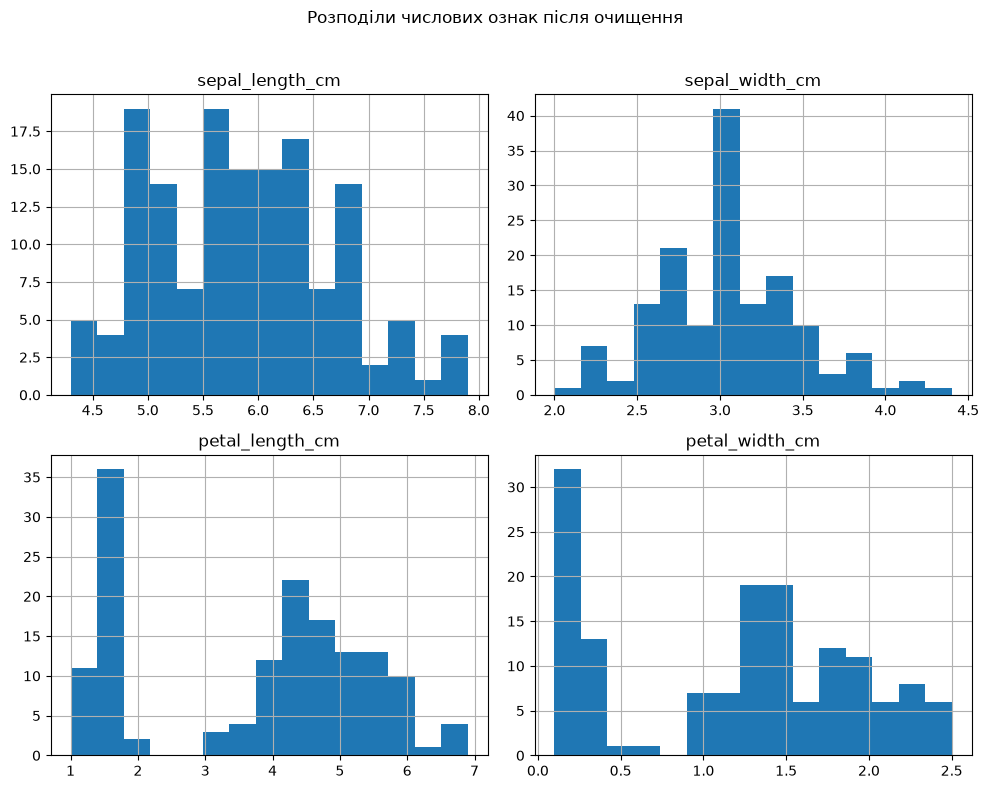

In [37]:
clean_df[numeric_columns].hist(
    bins=15,
    figsize=(10, 8)
)

plt.suptitle("Розподіли числових ознак після очищення")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(FIGURES_DIR / "pr02_histograms.png", dpi=150)
plt.show()

**Відповіді на запитання.**

1. Ні. Близькі до симетричних лише ознаки чашолистка; розподіли ознак пелюстки асиметричні та мають розрив.
2. Окремі групи помітні для `petal_length_cm` і `petal_width_cm`: група малих значень (довжина до 2 см, ширина до 0,6 см) відповідає setosa.
3. Найбільший діапазон має довжина пелюстки (1,0–6,9 см, розмах 5,9 см), далі — довжина чашолистка (4,3–7,9 см).
4. Очевидних надзвичайних значень не залишилося. Помітні високі стовпчики на рівні медіан (наприклад, 4,3 см довжини пелюстки) — це наслідок заповнення пропусків медіаною.

### 7.3. Діаграми розмаху

Діаграма розмаху показує медіану, перший і третій квартилі, міжквартильний розмах
і потенційно віддалені значення. Точка за межами «вусів» не завжди означає помилку.

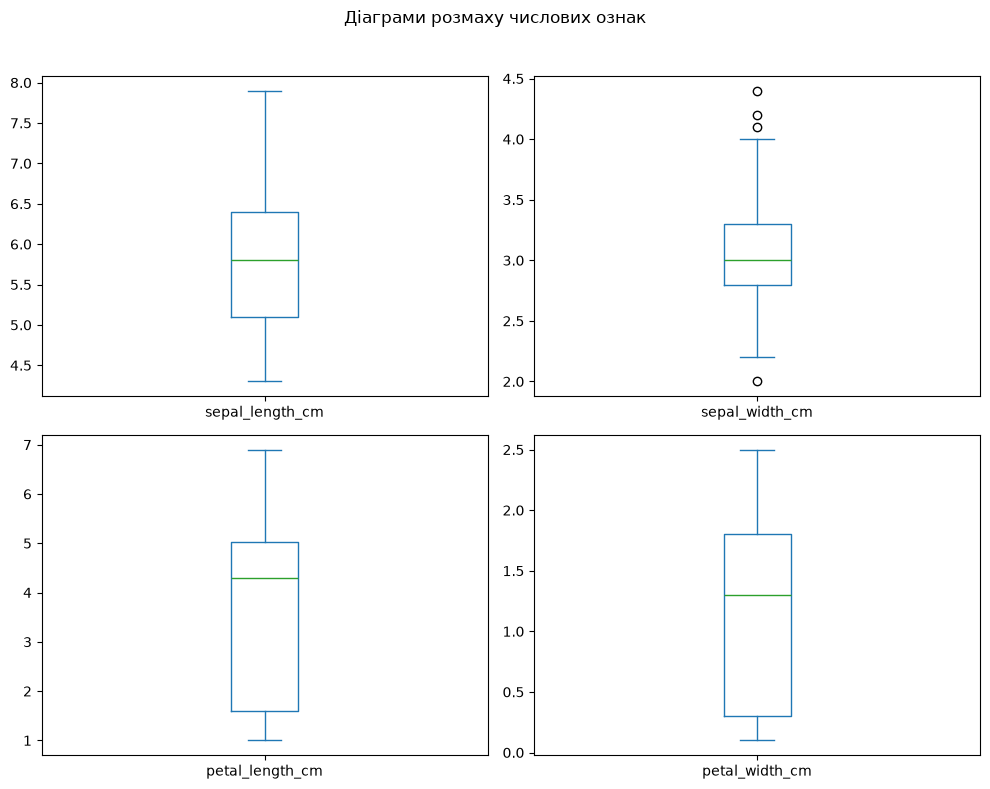

In [38]:
clean_df[numeric_columns].plot(
    kind="box",
    subplots=True,
    layout=(2, 2),
    figsize=(10, 8),
    sharex=False,
    sharey=False
)

plt.suptitle("Діаграми розмаху числових ознак")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(FIGURES_DIR / "pr02_boxplots.png", dpi=150)
plt.show()

Точки за «вусами» видно лише для `sepal_width_cm` (кілька значень близько 2,0 і понад 4,0 см).
Вони лежать у межах 3·IQR і відповідають реальним квіткам вихідного Iris, тому не видалялися.

### 7.4. Аналіз розподілу класів

In [39]:
class_distribution = pd.DataFrame(
    {
        "count": clean_df["species"].value_counts().sort_index(),
        "percent": (
            clean_df["species"]
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2)
        )
    }
)

display(class_distribution)

,count,percent
species,,
setosa,50,33.78
versicolor,49,33.11
virginica,49,33.11


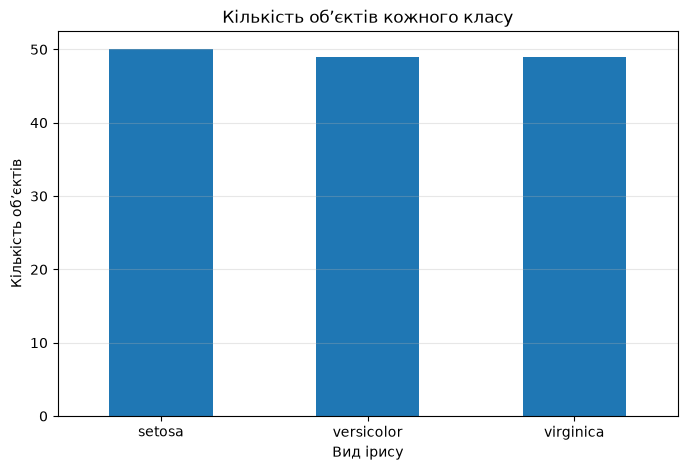

In [40]:
class_distribution["count"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Кількість об’єктів кожного класу")
plt.xlabel("Вид ірису")
plt.ylabel("Кількість об’єктів")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.savefig(FIGURES_DIR / "pr02_class_counts.png", dpi=150, bbox_inches="tight")
plt.show()

- Набір **збалансований**: setosa — 50 (33,78 %), versicolor — 49 (33,11 %), virginica — 49 (33,11 %).
- Після видалення двох рядків без класу (по одному versicolor і virginica у вихідних даних) баланс змінився лише на 0,67 відсоткового пункту.
- Усі три класи представлені.

### 7.5. Аналіз взаємозв'язків між ознаками

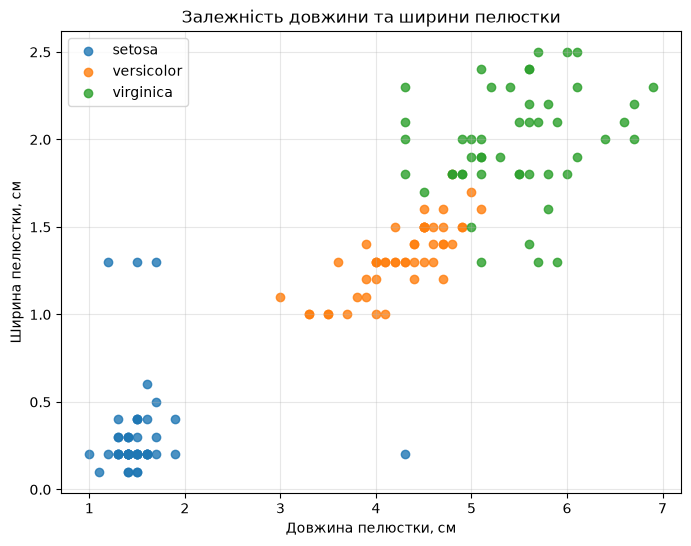

In [41]:
plt.figure(figsize=(8, 6))

for species_name, group in clean_df.groupby("species"):
    plt.scatter(
        group["petal_length_cm"],
        group["petal_width_cm"],
        label=species_name,
        alpha=0.8
    )

plt.title("Залежність довжини та ширини пелюстки")
plt.xlabel("Довжина пелюстки, см")
plt.ylabel("Ширина пелюстки, см")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(FIGURES_DIR / "pr02_petal_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

**Відповіді на запитання.**

1. Найкраще відокремлюється **setosa** — компактна група в лівому нижньому куті.
2. Частково перекриваються **versicolor** і **virginica** (довжина ≈ 4,5–5,1 см, ширина ≈ 1,4–1,8 см).
3. Так, ознаки пелюстки придатні для класифікації: вони чітко відокремлюють setosa і майже розділяють два інші види.
4. Залежність сильна, пряма й близька до лінійної: довша пелюстка зазвичай ширша.

Окремі «вибиті» точки — setosa з довжиною 4,3 см або шириною 1,3 см, virginica з шириною 1,3 см —
не реальні вимірювання, а результат заповнення пропусків загальними медіанами. Очищення забезпечує допустимість значень,
але не відновлює справжнє вимірювання конкретної квітки.

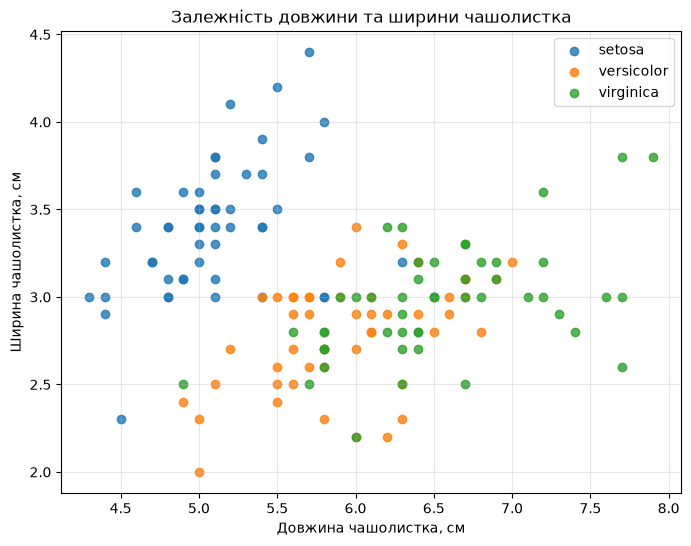

In [42]:
plt.figure(figsize=(8, 6))

for species_name, group in clean_df.groupby("species"):
    plt.scatter(
        group["sepal_length_cm"],
        group["sepal_width_cm"],
        label=species_name,
        alpha=0.8
    )

plt.title("Залежність довжини та ширини чашолистка")
plt.xlabel("Довжина чашолистка, см")
plt.ylabel("Ширина чашолистка, см")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(FIGURES_DIR / "pr02_sepal_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

За ознаками чашолистка добре відокремлюється лише setosa (короткі, але широкі чашолистки).
Точки versicolor і virginica значно перемішані, тому ознаки чашолистка розділяють класи
гірше, ніж ознаки пелюстки.

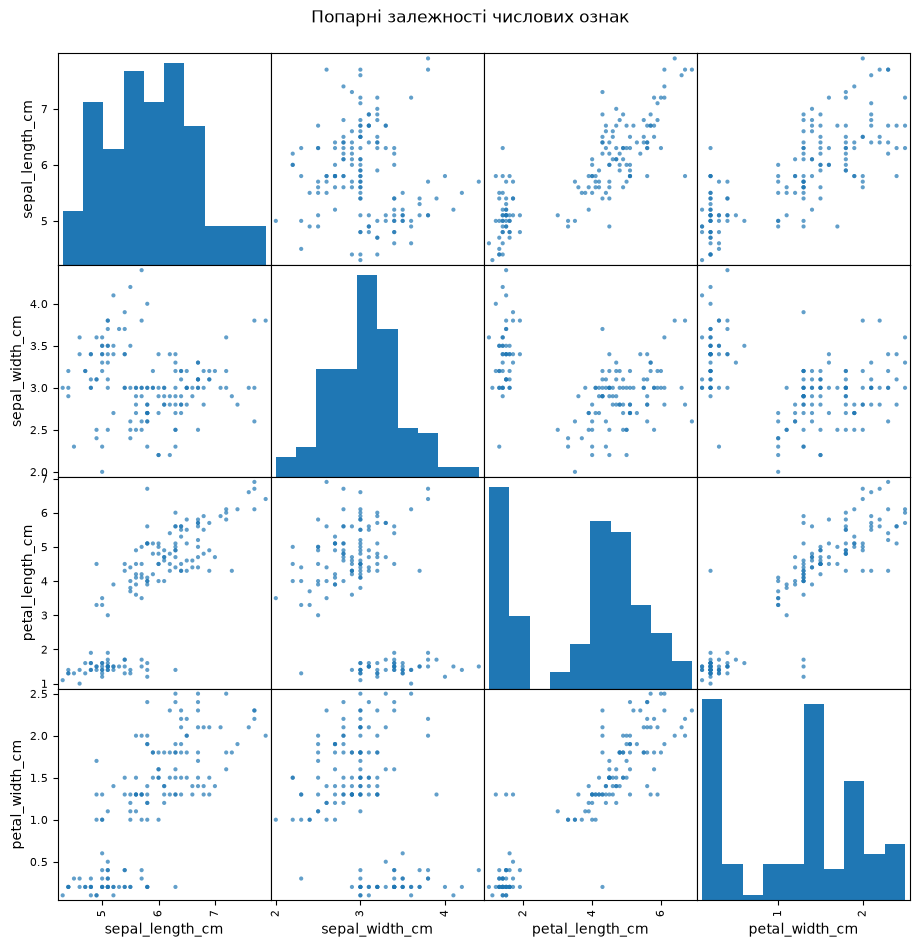

In [43]:
pd.plotting.scatter_matrix(
    clean_df[numeric_columns],
    figsize=(11, 11),
    diagonal="hist",
    alpha=0.7
)

plt.suptitle("Попарні залежності числових ознак", y=0.92)
plt.savefig(FIGURES_DIR / "pr02_scatter_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

### 7.6. Матриця кореляцій

In [44]:
correlation_matrix = (
    clean_df[numeric_columns]
    .corr()
)

display(correlation_matrix.round(3))

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
sepal_length_cm,1.000,-0.105,0.819,0.760
sepal_width_cm,-0.105,1.000,-0.403,-0.355
petal_length_cm,0.819,-0.403,1.000,0.917
petal_width_cm,0.760,-0.355,0.917,1.000


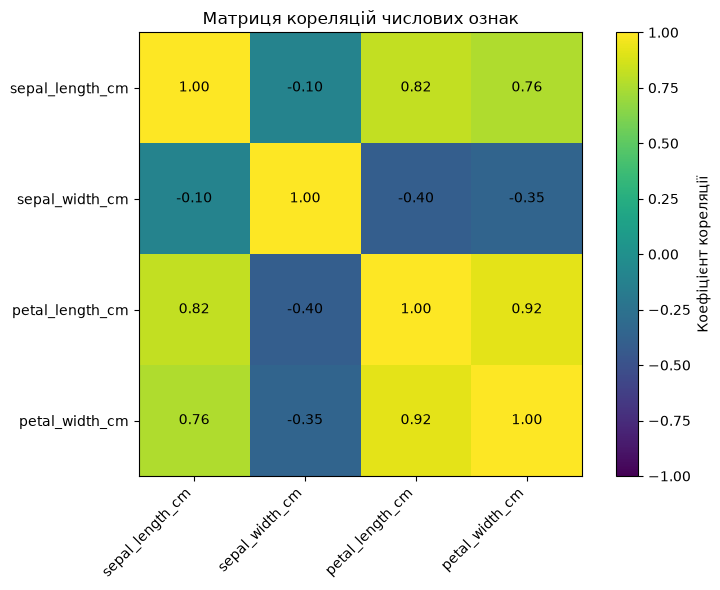

In [45]:
fig, ax = plt.subplots(figsize=(8, 6))

image = ax.imshow(
    correlation_matrix,
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(numeric_columns)))
ax.set_yticks(range(len(numeric_columns)))
ax.set_xticklabels(numeric_columns, rotation=45, ha="right")
ax.set_yticklabels(numeric_columns)

for row_index in range(len(numeric_columns)):
    for column_index in range(len(numeric_columns)):
        ax.text(
            column_index,
            row_index,
            f"{correlation_matrix.iloc[row_index, column_index]:.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(image, ax=ax, label="Коефіцієнт кореляції")
ax.set_title("Матриця кореляцій числових ознак")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "pr02_correlation_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

**Відповіді на запитання.**

1. Найсильніша додатна кореляція — між `petal_length_cm` і `petal_width_cm` (**0,917**); також сильно пов'язані довжина пелюстки й довжина чашолистка (0,819).
2. Найслабше корелюють `sepal_length_cm` і `sepal_width_cm` (−0,105); ширина чашолистка має слабкий від'ємний зв'язок з усіма іншими ознаками.
3. Кореляція, близька до 1, означає сильну пряму лінійну залежність: більшим значенням однієї ознаки відповідають більші значення іншої.
4. Ні, кореляція не доводить причинно-наслідкового зв'язку: обидві ознаки можуть залежати від спільного чинника (тут — від виду квітки).
5. Для лінійних моделей сильно корельовані ознаки майже дублюють одна одну (мультиколінеарність): коефіцієнти моделі стають нестійкими й важко інтерпретуються.

### 7.7. Аналіз категоріальної ознаки

In [46]:
device_distribution = pd.DataFrame(
    {
        "count": clean_df["measurement_device"].value_counts().sort_index(),
        "percent": (
            clean_df["measurement_device"]
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2)
        )
    }
)

display(device_distribution)

,count,percent
measurement_device,,
device_a,55,37.16
device_b,61,41.22
device_c,32,21.62


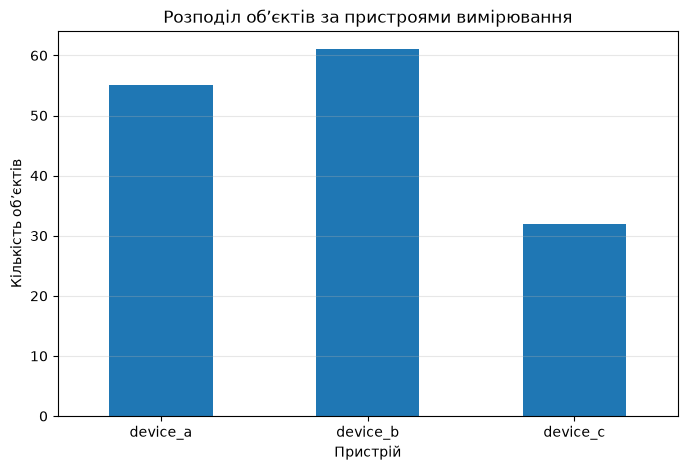

In [47]:
device_distribution["count"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Розподіл об’єктів за пристроями вимірювання")
plt.xlabel("Пристрій")
plt.ylabel("Кількість об’єктів")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.savefig(FIGURES_DIR / "pr02_device_counts.png", dpi=150, bbox_inches="tight")
plt.show()

Найчастіший пристрій — `device_b` (61 об'єкт, 41,22 %; з них 4 отримали це значення під час
заповнення модою), далі `device_a` — 55 (37,16 %) і `device_c` — 32 (21,62 %). Пристрій
згенеровано випадково, незалежно від виду квітки, тому корисності для класифікації ця ознака не має.

## 8. Кодування категоріальних ознак

Категоріальна ознака `measurement_device` кодується методом one-hot. Між пристроями немає
природного порядку, тому кодування числами 1, 2, 3 ввело б хибне припущення про порядок і відстань.
Цільова змінна `species` перетворюється на числові коди.

In [48]:
encoded_df = pd.get_dummies(
    clean_df,
    columns=["measurement_device"],
    dtype=int
)

display(encoded_df.head())

print("Стовпці після кодування:")
for column in encoded_df.columns:
    print("-", column)

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device_device_a,measurement_device_device_b,measurement_device_device_c
0,5.1,3.5,1.4,0.2,setosa,0,0,1
1,5.8,3.0,1.4,0.2,setosa,0,1,0
2,4.7,3.2,1.3,0.2,setosa,0,0,1
3,5.1,3.1,1.5,0.2,setosa,0,1,0
4,5.0,3.6,1.4,0.2,setosa,1,0,0


Стовпці після кодування:
- sepal_length_cm
- sepal_width_cm
- petal_length_cm
- petal_width_cm
- species
- measurement_device_device_a
- measurement_device_device_b
- measurement_device_device_c


In [49]:
class_mapping = {
    "setosa": 0,
    "versicolor": 1,
    "virginica": 2
}

encoded_df["species_code"] = (
    encoded_df["species"]
    .map(class_mapping)
)

display(
    encoded_df[["species", "species_code"]]
    .drop_duplicates()
    .sort_values("species_code")
)

,species,species_code
0,setosa,0
50,versicolor,1
99,virginica,2


### 8.1. Розділення ознак і цільової змінної

Зі складу `X` видаляються обидва стовпці `species` і `species_code`: вони містять правильний клас,
і їх використання як вхідної ознаки спричинило б прямий витік цільової інформації.

In [50]:
X = encoded_df.drop(
    columns=[
        "species",
        "species_code"
    ]
)

y = encoded_df["species_code"]

print("Розмір X:", X.shape)
print("Розмір y:", y.shape)

display(X.head())
display(y.head())

Розмір X: (148, 7)
Розмір y: (148,)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,measurement_device_device_a,measurement_device_device_b,measurement_device_device_c
0,5.1,3.5,1.4,0.2,0,0,1
1,5.8,3.0,1.4,0.2,0,1,0
2,4.7,3.2,1.3,0.2,0,0,1
3,5.1,3.1,1.5,0.2,0,1,0
4,5.0,3.6,1.4,0.2,1,0,0


0    0
1    0
2    0
3    0
4    0
Name: species_code, dtype: int64

## 9. Формування навчальної й тестової вибірок

Для тестування виділяється 20 % об'єктів. Використовується стратифікація, щоб зберегти
приблизно однакові частки класів.

**Примітка.** У межах цієї практичної роботи поділ виконується після очищення всього набору даних.
Отримані `X_train` і `X_test` призначені для демонстрації структури вибірок, збереження
співвідношення класів і підготовки файлів для наступної роботи. На цьому етапі `X_test`
ще не слід використовувати для остаточної незалежної оцінки якості моделі, оскільки параметри
очищення та заповнення пропусків було визначено до розбиття даних.

- `test_size=0.20` — приблизно 20 % об'єктів потрапляє до тестової вибірки;
- `random_state=42` — забезпечує відтворюваність розбиття;
- `stratify=y` — зберігає співвідношення класів.

In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (118, 7)
X_test: (30, 7)
y_train: (118,)
y_test: (30,)


### 9.1. Порівняння розподілів класів

In [52]:
reverse_class_mapping = {
    value: key
    for key, value in class_mapping.items()
}

train_counts = y_train.value_counts().sort_index()
test_counts = y_test.value_counts().sort_index()

class_split_report = pd.DataFrame(
    {
        "train_count": train_counts,
        "test_count": test_counts
    }
)

class_split_report.index = [
    reverse_class_mapping[index]
    for index in class_split_report.index
]

class_split_report["train_percent"] = (
    class_split_report["train_count"]
    / class_split_report["train_count"].sum()
    * 100
).round(2)

class_split_report["test_percent"] = (
    class_split_report["test_count"]
    / class_split_report["test_count"].sum()
    * 100
).round(2)

display(class_split_report)

,train_count,test_count,train_percent,test_percent
setosa,40,10,33.90,33.33
versicolor,39,10,33.05,33.33
virginica,39,10,33.05,33.33


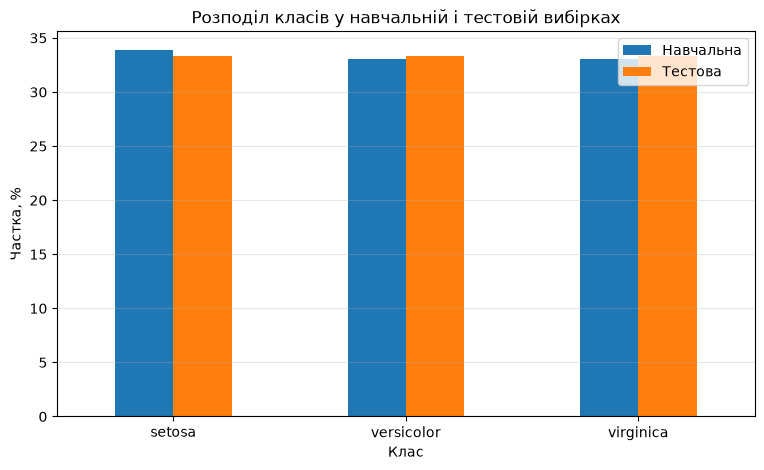

In [53]:
class_split_report[["train_percent", "test_percent"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Розподіл класів у навчальній і тестовій вибірках")
plt.xlabel("Клас")
plt.ylabel("Частка, %")
plt.xticks(rotation=0)
plt.legend(["Навчальна", "Тестова"])
plt.grid(axis="y", alpha=0.3)
plt.savefig(FIGURES_DIR / "pr02_class_split.png", dpi=150, bbox_inches="tight")
plt.show()

**Відповіді на запитання.**

1. Так, у train представлено всі класи: setosa — 40, versicolor — 39, virginica — 39.
2. Так, у test представлено всі класи — по 10 об'єктів кожного.
3. Частки дуже близькі: різниця не перевищує 0,57 відсоткового пункту (33,90 % проти 33,33 % для setosa) і зумовлена лише цілими кількостями об'єктів.
4. Параметр `stratify=y` змусив `train_test_split` розподілити кожен клас між train і test в одній пропорції 80/20.

### 9.2. Порівняння зі звичайним розбиттям

Цей етап виконується лише для демонстрації — у подальших роботах випадкове розбиття без стратифікації не використовується.

In [54]:
_, _, y_train_random, y_test_random = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=7
)

random_split_report = pd.DataFrame(
    {
        "train_percent": (
            y_train_random
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2)
        ),
        "test_percent": (
            y_test_random
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2)
        )
    }
)

random_split_report.index = [
    reverse_class_mapping[index]
    for index in random_split_report.index
]

display(random_split_report)

,train_percent,test_percent
setosa,36.44,23.33
versicolor,31.36,40.00
virginica,32.20,36.67


Без стратифікації (`random_state=7`) частки в тестовій вибірці помітно відхиляються:
setosa — 23,33 %, versicolor — 40,00 %, virginica — 36,67 % (7, 12 і 11 об'єктів).
Стратифіковане розбиття дає рівно по 33,33 %.

## 10. Формування звіту та збереження результатів

In [55]:
preprocessing_summary = pd.DataFrame(
    [
        {
            "stage": "Початковий пошкоджений набір",
            "row_count": len(raw_df),
            "missing_count": int(raw_df.isna().sum().sum()),
            "duplicate_count": int(raw_df.duplicated().sum())
        },
        {
            "stage": "Після видалення дублікатів",
            "row_count": rows_after_duplicates,
            "missing_count": None,
            "duplicate_count": 0
        },
        {
            "stage": "Після очищення",
            "row_count": len(clean_df),
            "missing_count": int(clean_df.isna().sum().sum()),
            "duplicate_count": int(clean_df.duplicated().sum())
        },
        {
            "stage": "Навчальна вибірка",
            "row_count": len(X_train),
            "missing_count": int(X_train.isna().sum().sum()),
            "duplicate_count": int(X_train.duplicated().sum())
        },
        {
            "stage": "Тестова вибірка",
            "row_count": len(X_test),
            "missing_count": int(X_test.isna().sum().sum()),
            "duplicate_count": int(X_test.duplicated().sum())
        }
    ]
)

display(preprocessing_summary)

,stage,row_count,missing_count,duplicate_count
0,Початковий пошкоджений набір,154,24.0,4
1,Після видалення дублікатів,150,NaN,0
2,Після очищення,148,0.0,0
3,Навчальна вибірка,118,0.0,0
4,Тестова вибірка,30,0.0,0


In [56]:
clean_df.to_csv(CLEANED_PATH, index=False)

X_train.to_csv(X_TRAIN_PATH, index=False)
X_test.to_csv(X_TEST_PATH, index=False)

y_train.rename("species_code").to_csv(Y_TRAIN_PATH, index=False)
y_test.rename("species_code").to_csv(Y_TEST_PATH, index=False)

preprocessing_summary.to_csv(SUMMARY_PATH, index=False)

with open(CLASS_MAPPING_PATH, "w", encoding="utf-8") as file:
    json.dump(
        class_mapping,
        file,
        ensure_ascii=False,
        indent=4
    )

output_files = [
    DIRTY_PATH,
    CLEANED_PATH,
    X_TRAIN_PATH,
    X_TEST_PATH,
    Y_TRAIN_PATH,
    Y_TEST_PATH,
    SUMMARY_PATH,
    CLASS_MAPPING_PATH
]

for path in output_files:
    print(path.name, "–", "створено" if path.exists() else "відсутній")

iris_dirty.csv – створено
iris_cleaned.csv – створено
X_train.csv – створено
X_test.csv – створено
y_train.csv – створено
y_test.csv – створено
preprocessing_summary.csv – створено
class_mapping.json – створено


### 10.1. Автоматична перевірка результатів

In [57]:
assert clean_df.isna().sum().sum() == 0, (
    "В очищеній таблиці залишилися пропуски."
)

assert clean_df.duplicated().sum() == 0, (
    "В очищеній таблиці залишилися дублікати."
)

assert set(clean_df["species"].unique()) == {
    "setosa",
    "versicolor",
    "virginica"
}, "Набір класів не відповідає очікуваному."

assert set(clean_df["measurement_device"].unique()) == {
    "device_a",
    "device_b",
    "device_c"
}, "Категорії пристроїв очищено неправильно."

assert all(
    pd.api.types.is_numeric_dtype(clean_df[column])
    for column in numeric_columns
), "Не всі числові стовпці мають числовий тип."

assert (clean_df[numeric_columns] > 0).all().all(), (
    "Залишилися фізично неможливі значення."
)

assert len(X_train) + len(X_test) == len(X), (
    "Кількість об’єктів після розбиття змінилася."
)

assert list(X_train.columns) == list(X_test.columns), (
    "Стовпці train і test не збігаються."
)

assert set(y_train.unique()) == {0, 1, 2}, (
    "У навчальній вибірці відсутній один із класів."
)

assert set(y_test.unique()) == {0, 1, 2}, (
    "У тестовій вибірці відсутній один із класів."
)

assert X_train.isna().sum().sum() == 0
assert X_test.isna().sum().sum() == 0

print("Усі основні перевірки виконано успішно.")

Усі основні перевірки виконано успішно.


## 11. Індивідуальні додаткові завдання

### Варіант 1. Функція аудиту даних

In [58]:
def data_quality_summary(dataset):
    """
    Повертає таблицю з типами даних, кількістю пропусків,
    відсотком пропусків, кількістю унікальних значень
    і кількістю дублікатів.
    """
    summary = pd.DataFrame(
        {
            "data_type": dataset.dtypes.astype(str),
            "missing_count": dataset.isna().sum(),
            "missing_percent": (
                dataset.isna().mean()
                .mul(100)
                .round(2)
            ),
            "unique_count": dataset.nunique()
        }
    )

    print("Кількість повних дублікатів:", dataset.duplicated().sum())

    return summary


display(data_quality_summary(raw_df))
display(data_quality_summary(clean_df))

Кількість повних дублікатів: 4


,data_type,missing_count,missing_percent,unique_count
sepal_length_cm,str,4,2.60,38
sepal_width_cm,float64,5,3.25,24
petal_length_cm,float64,4,2.60,43
petal_width_cm,float64,5,3.25,23
species,str,2,1.30,3
measurement_device,str,4,2.60,6


Кількість повних дублікатів: 0


,data_type,missing_count,missing_percent,unique_count
sepal_length_cm,Float64,0,0.0,35
sepal_width_cm,Float64,0,0.0,23
petal_length_cm,Float64,0,0.0,42
petal_width_cm,Float64,0,0.0,22
species,string,0,0.0,3
measurement_device,string,0,0.0,3


### Варіант 2. Порівняння середнього і медіани

In [59]:
mean_median_comparison = pd.DataFrame(
    {
        "mean": clean_df[numeric_columns].mean(),
        "median": clean_df[numeric_columns].median()
    }
)

mean_median_comparison["difference"] = (
    mean_median_comparison["mean"]
    - mean_median_comparison["median"]
)

display(mean_median_comparison.round(4))

,mean,median,difference
sepal_length_cm,5.8507,5.8,0.0507
sepal_width_cm,3.0507,3.0,0.0507
petal_length_cm,3.7311,4.3,-0.5689
petal_width_cm,1.198,1.3,-0.102


Для ознак чашолистка різниця мала (+0,05 см) — їхні розподіли близькі до симетричних.
Найбільша різниця — для довжини пелюстки (−0,57 см) і помітна для ширини пелюстки (−0,10 см):
середнє менше за медіану, тобто розподіли асиметричні з «хвостом» у бік малих значень,
який утворюють короткі пелюстки setosa.

### Варіант 3. Порівняння train/test без стратифікації

In [60]:
random_states = [0, 1, 2, 3, 7, 42]
split_rows = []

for state in random_states:
    _, _, _, y_test_state = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=state
    )
    test_percent = (
        y_test_state
        .value_counts(normalize=True)
        .reindex([0, 1, 2], fill_value=0)
        .mul(100)
        .round(2)
    )
    split_rows.append(
        {
            "random_state": state,
            "setosa_%": test_percent[0],
            "versicolor_%": test_percent[1],
            "virginica_%": test_percent[2],
            "max_deviation_pp": round((test_percent - 100 / 3).abs().max(), 2)
        }
    )

random_splits = pd.DataFrame(split_rows)

display(random_splits)

,random_state,setosa_%,versicolor_%,virginica_%,max_deviation_pp
0,0,36.67,36.67,26.67,6.66
1,1,33.33,40.00,26.67,6.67
2,2,40.00,30.00,30.00,6.67
3,3,40.00,16.67,43.33,16.66
4,7,23.33,40.00,36.67,10.00
5,42,36.67,33.33,30.00,3.34


Без стратифікації частки класів у тесті коливаються від 16,67 % до 43,33 %; найгірший
випадок (`random_state=3`) містить лише 5 versicolor і 13 virginica. Стратифіковане розбиття
стабільно дає по 10 об'єктів кожного класу, тому оцінка якості не залежить від «вдалого» seed.

### Варіант 4. Збереження рисунків

Усі рисунки цієї роботи зберігаються у папку `reports/figures` (виклик `plt.savefig` перед `plt.show()`).

In [61]:
for path in sorted(FIGURES_DIR.glob("pr02_*.png")):
    print(path.name)

pr02_boxplots.png
pr02_class_counts.png
pr02_class_split.png
pr02_correlation_matrix.png
pr02_device_counts.png
pr02_histograms.png
pr02_missing.png
pr02_petal_scatter.png
pr02_scatter_matrix.png
pr02_sepal_scatter.png


### Варіант 5. Порівняння способів заповнення

Створюються дві копії очищеного набору до заповнення пропусків: в одній пропуски
заповнюються середнім, в іншій — медіаною.

In [62]:
before_imputation = raw_df.drop_duplicates().reset_index(drop=True)

for column in numeric_columns:
    before_imputation[column] = pd.to_numeric(
        before_imputation[column]
        .astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

before_imputation = before_imputation.dropna(subset=["species"]).reset_index(drop=True)

for column in numeric_columns:
    mask, _, _ = extreme_outlier_mask(before_imputation[column])
    before_imputation.loc[mask | (before_imputation[column] <= 0), column] = np.nan

mean_filled = before_imputation.copy()
median_filled = before_imputation.copy()

mean_filled[numeric_columns] = mean_filled[numeric_columns].fillna(
    mean_filled[numeric_columns].mean()
)
median_filled[numeric_columns] = median_filled[numeric_columns].fillna(
    median_filled[numeric_columns].median()
)

imputation_comparison = pd.DataFrame(
    {
        "mean_fill_mean": mean_filled[numeric_columns].mean(),
        "median_fill_mean": median_filled[numeric_columns].mean(),
        "mean_fill_std": mean_filled[numeric_columns].std(),
        "median_fill_std": median_filled[numeric_columns].std(),
        "mean_fill_median": mean_filled[numeric_columns].median(),
        "median_fill_median": median_filled[numeric_columns].median()
    }
)

display(imputation_comparison.round(4))

,mean_fill_mean,median_fill_mean,mean_fill_std,median_fill_std,mean_fill_median,median_fill_median
sepal_length_cm,5.8524,5.8507,0.7973,0.7974,5.8,5.8
sepal_width_cm,3.0528,3.0507,0.4239,0.424,3.0,3.0
petal_length_cm,3.7112,3.7311,1.7366,1.7398,4.2,4.3
petal_width_cm,1.1937,1.198,0.7387,0.739,1.3,1.3


Обидва способи дають майже однакові статистики: середні відрізняються не більше ніж на 0,02 см,
стандартні відхилення — не більше ніж на 0,004 см. Найпомітніша різниця — для довжини пелюстки:
заповнення середнім (3,71 см) зсуває медіану ознаки з 4,3 до 4,2 см і вставляє значення,
яке лежить у «проміжку» між setosa та іншими видами. Медіана стійкіша до аномалій, тому для
цієї роботи вона є кращим вибором.

# Висновки

Під час виконання практичної роботи було проведено дослідницький аналіз і підготовку набору
даних Iris до навчання моделей машинного навчання.

Для відпрацювання методів очищення було створено контрольовано пошкоджену версію набору,
яка містила пропущені значення, дублікати, текстові записи у числовому стовпці, неузгоджені
назви категорій і аномальні числові значення.

Під час аудиту було визначено типи даних, кількість пропусків, кількість унікальних значень
і повні дублікати. Числові стовпці було перетворено до правильних типів, а некоректні текстові
записи перетворено на пропущені значення.

Назви категорій пристроїв було уніфіковано. Об'єкти без відомого значення цільової змінної
видалено. Фізично неможливі та екстремальні значення було виявлено за допомогою логічних
правил і міжквартильного розмаху.

Пропуски числових ознак заповнено медіанами, а пропуски категоріальної ознаки — модою.
Після очищення в таблиці не залишилося пропущених значень і повних дублікатів.

Було побудовано гістограми, діаграми розмаху, діаграми залежностей між ознаками, розподіл
класів і матрицю кореляцій. Встановлено, що довжина та ширина пелюстки мають сильний
взаємозв'язок і добре відокремлюють клас setosa.

Категоріальну ознаку `measurement_device` було закодовано методом one-hot, а цільову змінну
`species` перетворено на числові коди. Після цього набір було розділено на матрицю ознак `X`
і цільову змінну `y`. Сформовано навчальну та тестову вибірки у співвідношенні 80 % і 20 %.
Завдяки стратифікованому розбиттю в обох вибірках збережено близьке співвідношення трьох класів.

У цій роботі розбиття виконано після очищення та кодування всього набору даних як навчальне
спрощення. Тому сформована тестова вибірка демонструє принцип поділу даних і стратифікації,
але ще не використовується для остаточного незалежного оцінювання моделі. У наступних роботах
параметри заповнення пропусків і кодування категорій визначатимуться лише за навчальною
вибіркою за допомогою конвеєра Pipeline.

Очищений набір, навчальна і тестова вибірки, словник класів та звіт про підготовку було
збережено для використання в наступних практичних роботах.

**Конкретні результати:**

- пошкоджений набір містив 154 рядки, 24 пропуски та 4 зайві дублікати; **видалено 4 дублікати**;
- **видалено 2 рядки** без цільової змінної;
- знайдено **1 нечислове значення** (`unknown`) і **3 аномалії**: −1,0 см довжини пелюстки (фізично неможливе), 18,0 см ширини чашолистка та 9,5 см ширини пелюстки (поза межами 3·IQR);
- медіанами заповнено 22 пропуски числових ознак, модою `device_b` — 4 пропуски пристрою;
- **залишилося 148 рядків** без пропусків і дублікатів; матриця `X` має 7 ознак;
- найсильніша кореляція — між довжиною та шириною пелюстки (**r = 0,917**);
- **баланс класів збережено**: 50 / 49 / 49 у всьому наборі, 40 / 39 / 39 у train і 10 / 10 / 10 у test.